# Detecting Depression-Related Language in Tweets Using Machine Learning

### Can we predict depression-related language using words written on Twitter?

This project started as a coursework exploration of decision trees and n-grams. Our aim is to classify the **tweets**, not to diagnose their authors. I keep the original step-by-step explanations, confusion matrices, and decision-tree visualizations while correcting how features are selected.

In [1]:
%matplotlib inline
# Importing Libraries
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.feature_extraction.text import CountVectorizer
import operator # useful functions

# Fixed parameters to make the experiment reproducible
RANDOM_STATE = 42
TOP_K = 5

In [2]:
tweets_df = pd.read_csv('sentiment_tweets3.csv')
tweets_df

,Index,message,label
0,106,just had a real good moment. i missssssssss hi...,0
1,217,is reading manga http://plurk.com/p/mzp1e,0
2,220,@comeagainjen http://twitpic.com/2y2lx - http:...,0
3,288,@lapcat Need to send 'em to my accountant tomo...,0
4,540,ADD ME ON MYSPACE!!! myspace.com/LookThunder,0
...,...,...,...
10309,802309,No Depression by G Herbo is my mood from now o...,1
10310,802310,What do you do when depression succumbs the br...,1
10311,802311,Ketamine Nasal Spray Shows Promise Against Dep...,1
10312,802312,dont mistake a bad day with depression! everyo...,1


In [3]:
# We need a training dataset and a testing dataset. Let's do 80 percent training and 20 percent testing.
# First check for duplicates so that the same text doesn't appear in both datasets.
tweets_df = tweets_df[["message", "label"]].dropna().copy()
tweets_df["message"] = tweets_df["message"].astype(str).str.strip()
tweets_df = tweets_df[tweets_df["message"] != ""].copy()
tweets_df["label"] = tweets_df["label"].astype(int)
print("Rows before removing duplicate tweets:", len(tweets_df))
print("Class counts before cleaning:\n", tweets_df["label"].value_counts())

# Remove identical texts with inconsistent labels, rather than choosing one label arbitrarily.
conflicts = tweets_df.groupby("message")["label"].nunique()
conflicting_text = set(conflicts[conflicts > 1].index)
print("Texts with conflicting labels:", len(conflicting_text))
tweets_df = tweets_df[~tweets_df["message"].isin(conflicting_text)]
tweets_df = tweets_df.drop_duplicates(subset="message").reset_index(drop=True)
print("Rows after removing duplicate tweets:", len(tweets_df))
print("Class counts after cleaning:\n", tweets_df["label"].value_counts())

Xraw_train, Xraw_test, Yraw_train, Yraw_test = train_test_split(
    tweets_df["message"], tweets_df["label"], test_size=0.2,
    random_state=RANDOM_STATE, stratify=tweets_df["label"]
)
assert set(Xraw_train).isdisjoint(set(Xraw_test))

Rows before removing duplicate tweets: 10314
Class counts before cleaning:
 label
0    8000
1    2314
Name: count, dtype: int64
Texts with conflicting labels: 1
Rows after removing duplicate tweets: 10280
Class counts after cleaning:
 label
0    7994
1    2286
Name: count, dtype: int64


In [4]:
# This function parses our tweets into n-grams (one, two or three words).
# We use the same tokenization for both classes and for training and testing.
def generate_N_grams(text, ngram=1):
    vectorizer = CountVectorizer(ngram_range=(ngram, ngram), stop_words="english")
    words = vectorizer.build_analyzer()(str(text))
    return words

# Inspired by the original n-gram exercise:
# https://www.analyticsvidhya.com/blog/2021/09/what-are-n-grams-and-how-to-implement-them-in-python/

In [5]:
# Feature selection happens ONCE using training tweets and training labels.
# The same selected n-grams are then used to transform the training and test tweets.
def from_tweets2features(X, Y, n, selected_ngrams=None):
    df = pd.DataFrame({"message": X.to_numpy(), "label": Y.to_numpy()})
    if selected_ngrams is None:
        dep_tweets = df[df.label == 1].message
        neut_tweets = df[df.label == 0].message

        # Counting the most frequent n-grams in each class, as in my original exercise.
        ngrams_dep = Counter()
        ngrams_neut = Counter()
        for t in dep_tweets:
            ngrams_dep.update(generate_N_grams(t, n))
        for t in neut_tweets:
            ngrams_neut.update(generate_N_grams(t, n))  # n, not always 1

        # Choose the top five from each category, using a deterministic tie-break.
        top_five_dep = sorted(ngrams_dep, key=lambda w: (-ngrams_dep[w], w))[:TOP_K]
        top_five_neut = sorted(ngrams_neut, key=lambda w: (-ngrams_neut[w], w))[:TOP_K]
        selected_ngrams = list(dict.fromkeys(top_five_dep + top_five_neut))
        print(f"Top depression-related {n}-grams:", top_five_dep)
        print(f"Top neutral {n}-grams:", top_five_neut)

    # Use token-based n-gram matches, not substring matching.
    # This also guarantees the same columns (same meanings) in train and test.
    feature_rows = []
    for text in df.message:
        grams = set(generate_N_grams(text, n))
        feature_rows.append([int(term in grams) for term in selected_ngrams])
    feature_columns = [f"ngram_{i+1}" for i in range(len(selected_ngrams))]
    features = pd.DataFrame(feature_rows, columns=feature_columns)
    features["label"] = df["label"]
    return features, selected_ngrams

In [6]:
def Depression_predictor(df_train, df_test, feature_names=None, title="Decision Tree"):
    # First, let's state which variables we use to predict and which one is the target.
    X_train = df_train.drop("label", axis=1)
    Y_train = df_train["label"]
    X_test = df_test.drop("label", axis=1)
    Y_test = df_test["label"]

    # Create and train the decision tree.
    model = DecisionTreeClassifier(random_state=RANDOM_STATE)
    model.fit(X_train, Y_train)

    # Predict and evaluate
    Y_pred = model.predict(X_test)
    accuracy = accuracy_score(Y_test, Y_pred)
    print("Accuracy:", accuracy)
    print("Balanced accuracy:", balanced_accuracy_score(Y_test, Y_pred))
    print("\nConfusion matrix (rows = true labels, columns = predictions):\n",
          confusion_matrix(Y_test, Y_pred, labels=[0, 1]))
    print("\nClassification report:\n", classification_report(Y_test, Y_pred, zero_division=0))

    # Original visualization 1: confusion matrix
    disp = ConfusionMatrixDisplay.from_predictions(
        Y_test, Y_pred, labels=[0, 1], display_labels=["non-depression", "depression"]
    )
    disp.ax_.set_title(title + " — Confusion Matrix")
    plt.show()

    # Original visualization 2: show the learned decision tree.
    # plot_tree is preserved, with the REAL n-grams as feature names when available.
    plt.figure(figsize=(16, 10))
    plot_tree(
        model, feature_names=feature_names if feature_names is not None else list(X_train.columns),
        class_names=["non-depression", "depression"],
        filled=True, rounded=True, fontsize=8
    )
    plt.title(title + " — Decision Tree")
    plt.show()
    return accuracy, model

In [7]:
# Assigning 3 different N-grams for the demonstration, as in the original notebook
df_train = {}
df_test = {}
selected_features = {}

for i in range(3):
    n = i + 1
    df_train[n], selected_features[n] = from_tweets2features(Xraw_train, Yraw_train, n)
    # Do NOT use test labels to select the top words!
    df_test[n], _ = from_tweets2features(Xraw_test, Yraw_test, n, selected_features[n])

Top depression-related 1-grams: ['depression', 'com', 'twitter', 'https', 'anxiety']
Top neutral 1-grams: ['just', 'good', 'day', 'http', 'love']


Top depression-related 2-grams: ['twitter com', 'pic twitter', 'depression anxiety', 'anxiety depression', 'https www']
Top neutral 2-grams: ['http twitpic', 'twitpic com', 'bit ly', 'http bit', 'good morning']


Top depression-related 3-grams: ['pic twitter com', 'https twitter com', 'depression pic twitter', 'emoji loudly crying', 'loudly crying face']
Top neutral 3-grams: ['http twitpic com', 'http bit ly', 'http blip fm', 'http tinyurl com', 'http plurk com']


## For 1-gram

Accuracy: 0.9961089494163424
Balanced accuracy: 0.9912472647702407

Confusion matrix (rows = true labels, columns = predictions):
 [[1599    0]
 [   8  449]]

Classification report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      1599
           1       1.00      0.98      0.99       457

    accuracy                           1.00      2056
   macro avg       1.00      0.99      0.99      2056
weighted avg       1.00      1.00      1.00      2056



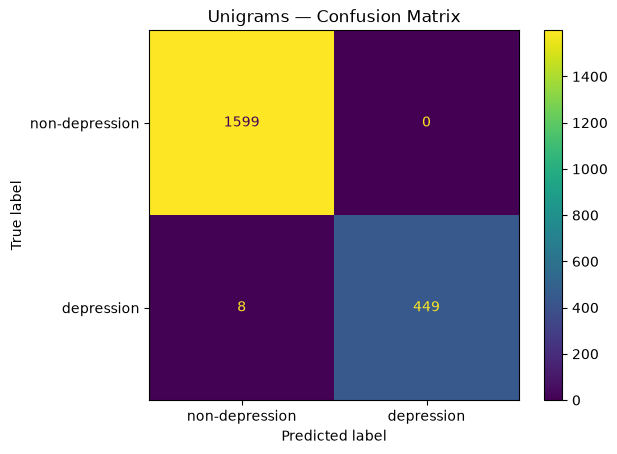

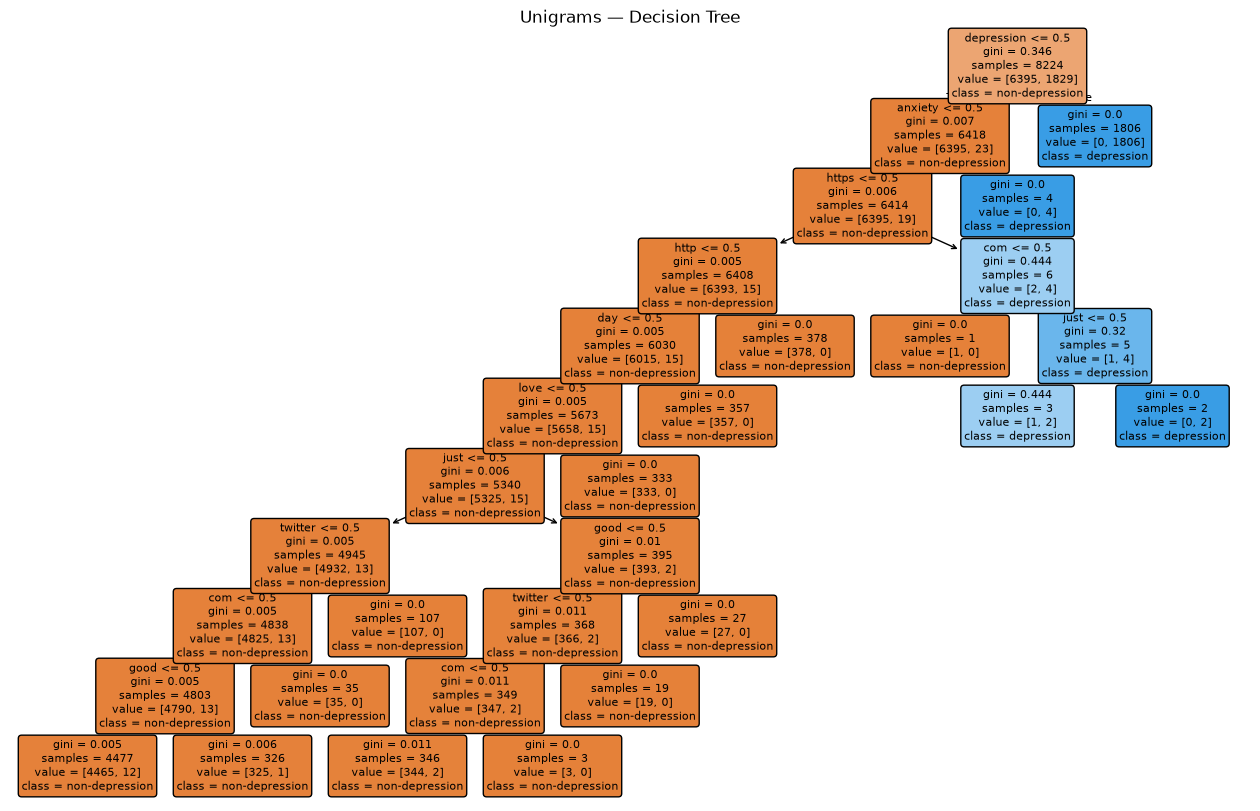

In [8]:
unigram_accuracy, unigram_tree = Depression_predictor(
    df_train[1], df_test[1], selected_features[1], "Unigrams"
)

### Results interpretation

The original notebook's confusion matrix and reported accuracy were produced with features selected separately on the test set. Those numerical results are **not valid holdout estimates**, so they are not reproduced here. Run the corrected cell above for the new accuracy and confusion matrix.

In each confusion matrix, rows are the true dataset classes (0 = non-depression-related, 1 = depression-related); columns are predicted classes. **Tweets are being classified, not people diagnosed.**

## For pairs (2-grams)

Accuracy: 0.8521400778210116
Balanced accuracy: 0.6673960612691466

Confusion matrix (rows = true labels, columns = predictions):
 [[1599    0]
 [ 304  153]]

Classification report:
               precision    recall  f1-score   support

           0       0.84      1.00      0.91      1599
           1       1.00      0.33      0.50       457

    accuracy                           0.85      2056
   macro avg       0.92      0.67      0.71      2056
weighted avg       0.88      0.85      0.82      2056



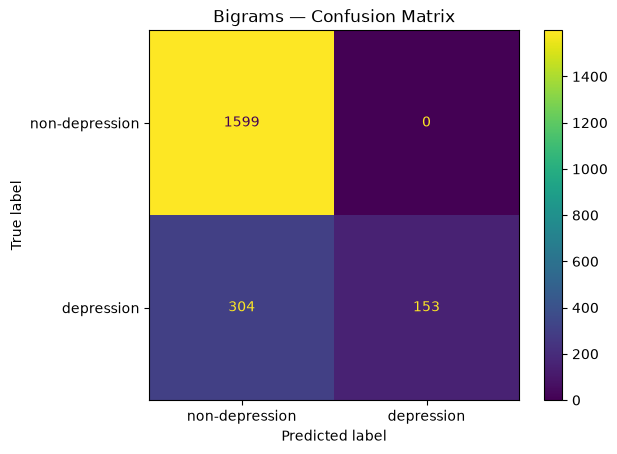

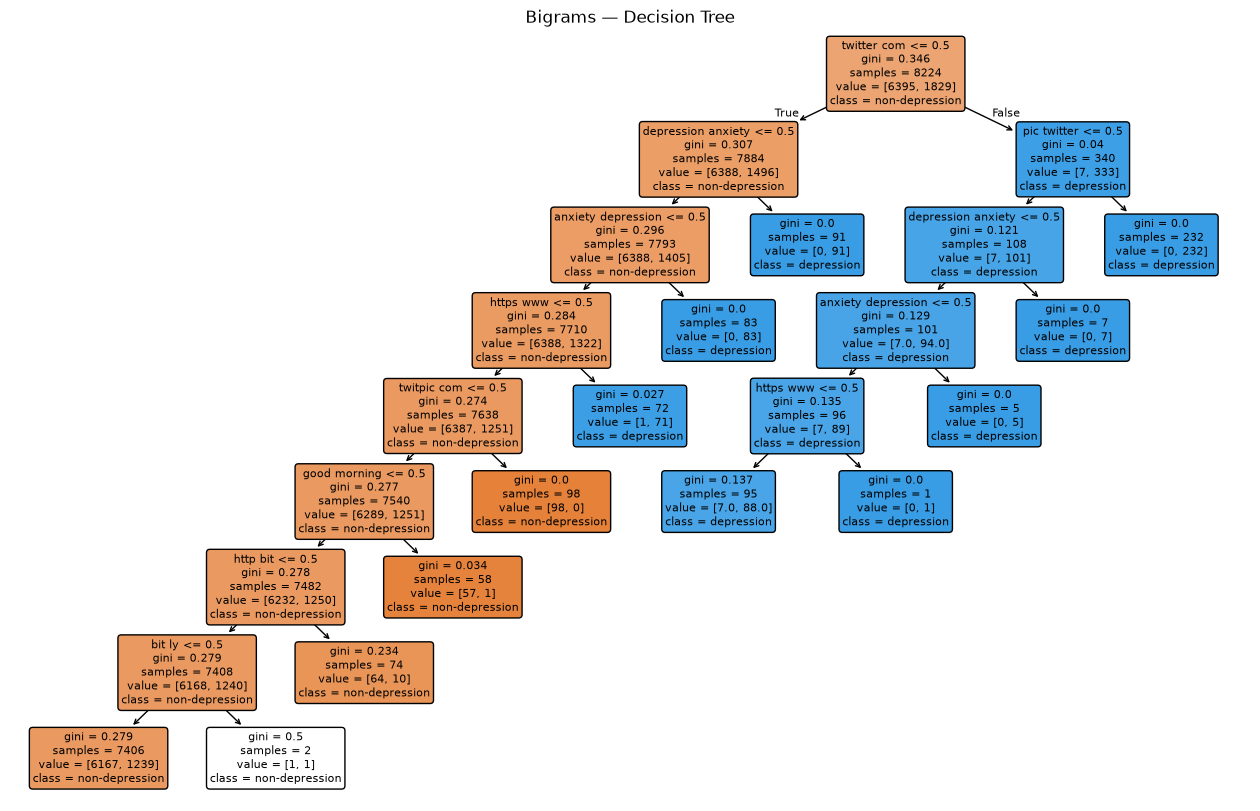

In [9]:
bigram_accuracy, bigram_tree = Depression_predictor(
    df_train[2], df_test[2], selected_features[2], "Bigrams"
)

## For Triplets (3-grams)

Accuracy: 0.8180933852140078
Balanced accuracy: 0.5908096280087527

Confusion matrix (rows = true labels, columns = predictions):
 [[1599    0]
 [ 374   83]]

Classification report:
               precision    recall  f1-score   support

           0       0.81      1.00      0.90      1599
           1       1.00      0.18      0.31       457

    accuracy                           0.82      2056
   macro avg       0.91      0.59      0.60      2056
weighted avg       0.85      0.82      0.76      2056



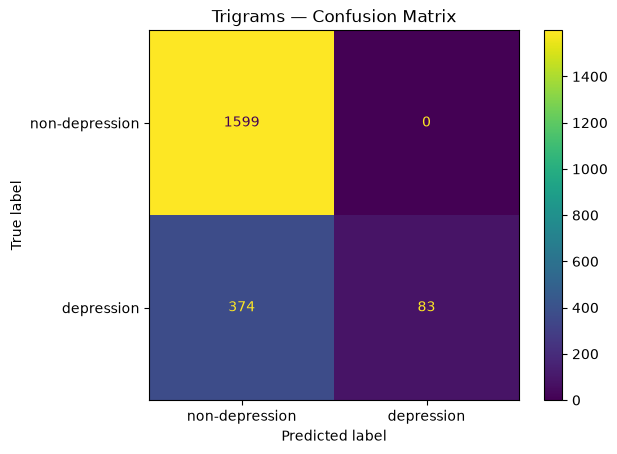

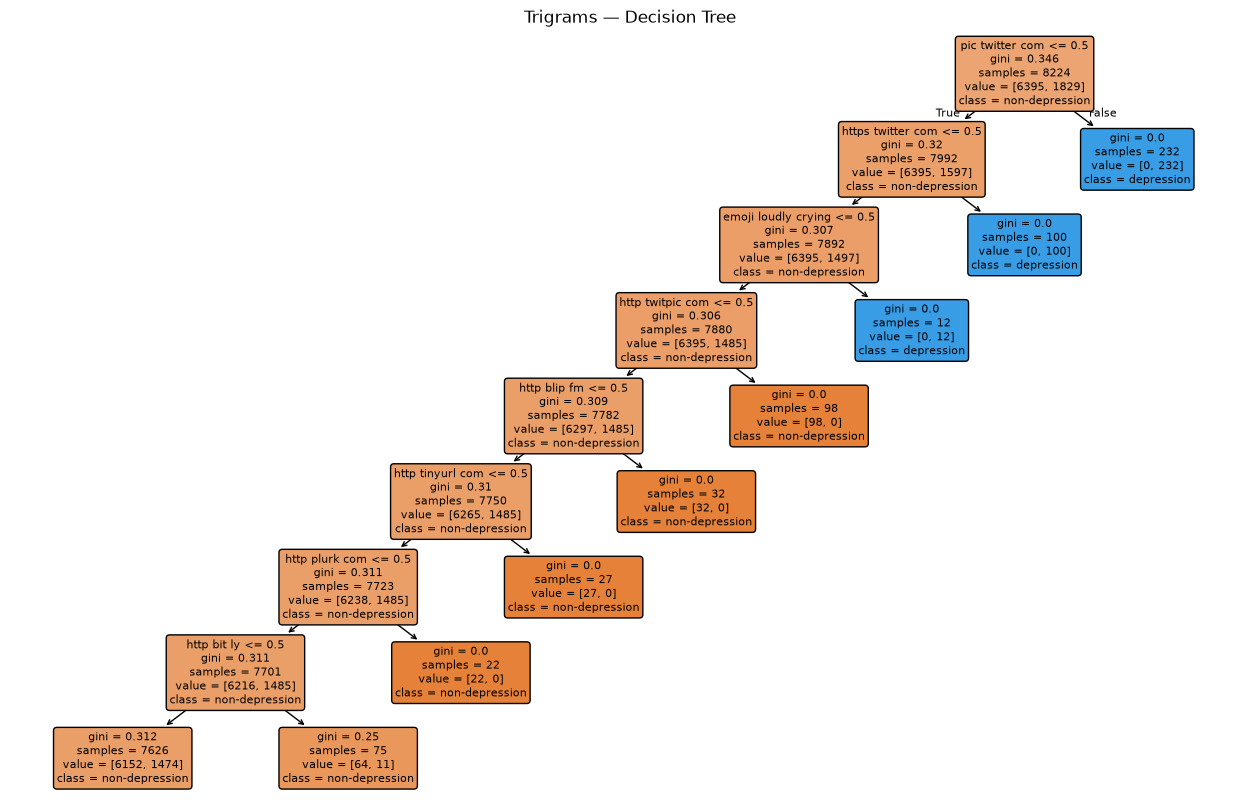

In [10]:
trigram_accuracy, trigram_tree = Depression_predictor(
    df_train[3], df_test[3], selected_features[3], "Trigrams"
)

## Additional experiment: what if we remove the word depression?

The word *depression* may be legitimate evidence in a tweet-level classification task. This experiment simply checks how strongly the model relies on explicit depression-related terms. We remove complete occurrences of **depression**, **depressed** and **depressive**, reselect the top unigrams from training data only, and plot the resulting confusion matrix and decision tree again.

Tweets containing terms in training: 1806
Tweets containing terms in testing: 449


Top depression-related 1-grams: ['com', 'twitter', 'https', 'anxiety', 'emoji']
Top neutral 1-grams: ['just', 'good', 'day', 'http', 'love']


Accuracy: 0.8842412451361867
Balanced accuracy: 0.7396061269146608

Confusion matrix (rows = true labels, columns = predictions):
 [[1599    0]
 [ 238  219]]

Classification report:
               precision    recall  f1-score   support

           0       0.87      1.00      0.93      1599
           1       1.00      0.48      0.65       457

    accuracy                           0.88      2056
   macro avg       0.94      0.74      0.79      2056
weighted avg       0.90      0.88      0.87      2056



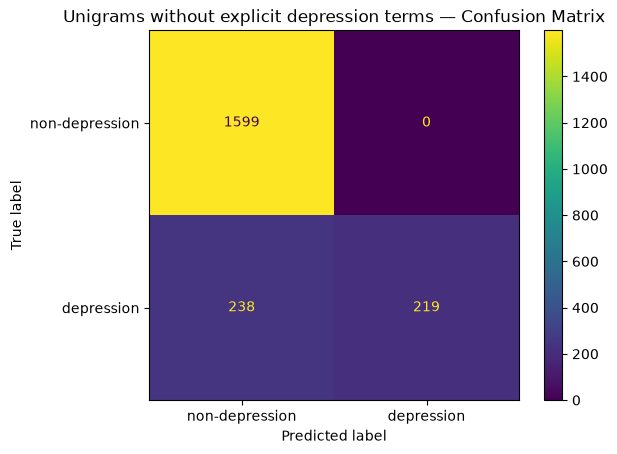

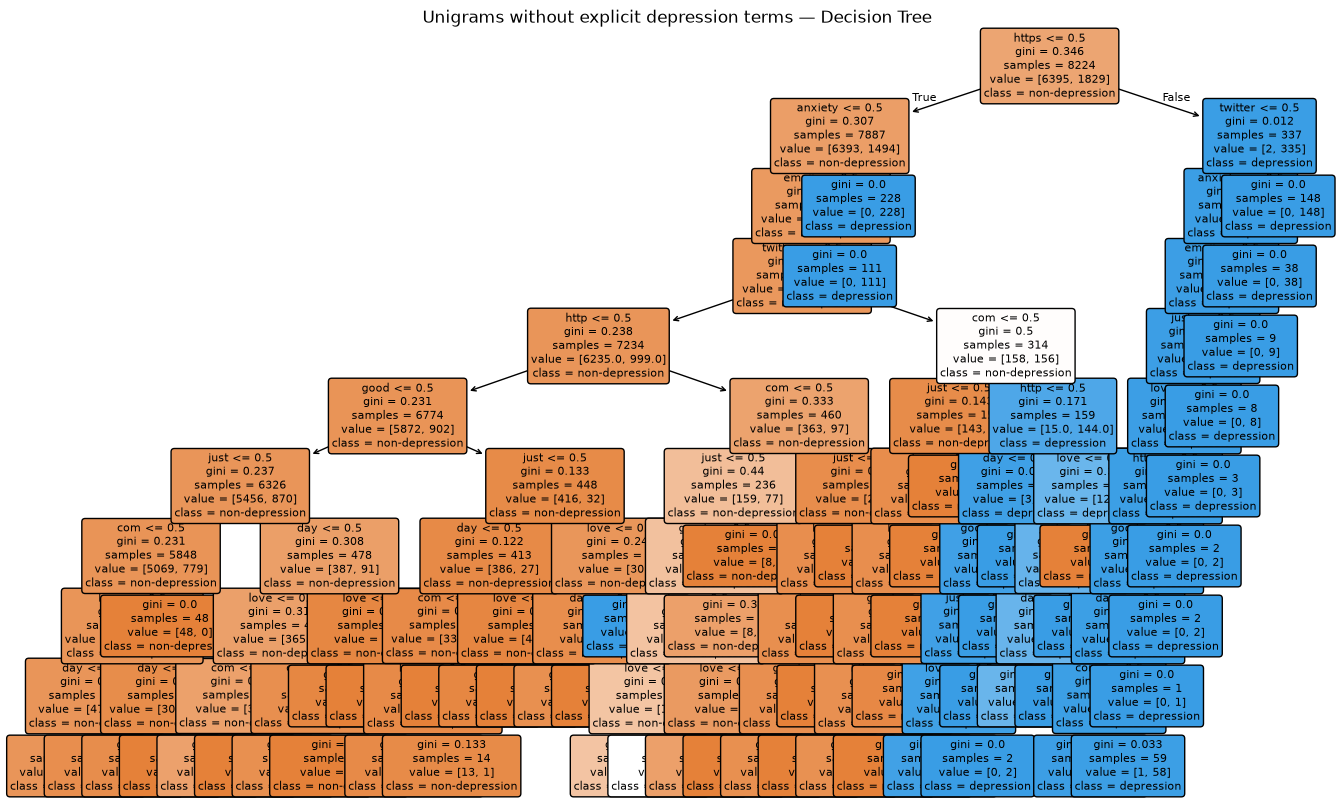

Original unigram accuracy: 0.9961089494163424
Without explicit terms: 0.8842412451361867
Difference in percentage points: -11.186770428015569


In [11]:
# This is an ablation experiment, not a change to the main model.
depression_terms = re.compile(r"\b(?:depression|depressed|depressive)\b", re.IGNORECASE)
Xtrain_without_terms = Xraw_train.map(lambda t: depression_terms.sub(" ", t))
Xtest_without_terms = Xraw_test.map(lambda t: depression_terms.sub(" ", t))

print("Tweets containing terms in training:", Xraw_train.str.contains(depression_terms).sum())
print("Tweets containing terms in testing:", Xraw_test.str.contains(depression_terms).sum())

df_train_without, terms_without = from_tweets2features(
    Xtrain_without_terms, Yraw_train, 1
)
df_test_without, _ = from_tweets2features(
    Xtest_without_terms, Yraw_test, 1, terms_without
)
ablation_accuracy, ablation_tree = Depression_predictor(
    df_train_without, df_test_without, terms_without,
    "Unigrams without explicit depression terms"
)
print("Original unigram accuracy:", unigram_accuracy)
print("Without explicit terms:", ablation_accuracy)
print("Difference in percentage points:", (ablation_accuracy - unigram_accuracy) * 100)

## Comparing results and limitations

An accuracy decrease when explicit depression words are removed would indicate that these words are informative in this dataset. It would not, on its own, invalidate their use: a tweet stating "I have depression" can be relevant to the tweet's label. Conversely, a general statement about depression does not imply the author has depression.

A high test accuracy predicts the **dataset's labels**, not the clinical depression status of the authors. Dataset annotation, collection bias, class balance, and distribution shift remain important limitations.

*Coursework context:* Fundamentals of Network Analysis and Data Mining, University of Calgary, taught by Professor Emma Towlson.